<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

## 1. 公司名称

**贵州茅台酒股份有限公司**（股票简称"贵州茅台"，股票代码 **600519.SH**，上海证券交易所主板）

## 2. 公司基本简介

| 项目 | 内容 |
|---|---|
| 上市日期 | 2001年8月27日 |
| 所属行业 | 食品饮料 — 白酒 |
| 总部所在地 | 贵州省仁怀市茅台镇 |
| 主营业务 | 贵州茅台酒及系列酒（茅台1935、汉酱、王子酒等）的生产与销售 |

**公司特点：**

1. **业绩稳定增长**：是国内确定性最强的消费龙头之一，本作业实测其2018年以来季度净利增速均值约16%、ROE均值约21%、毛利率高达约91%；
2. **A股标杆**：长期位居A股市值前列，是白酒板块乃至整个消费板块的风向标，关注度高、数据质量好；
3. **股价周期完整**：既经历了2019—2020年的大幅上涨，也经历了2021年以来的持续回调，完整覆盖"估值扩张—估值消化"周期，为研究股价涨跌的驱动因素提供了理想样本。

**选择理由：** tushare中该公司的行情、估值、财务、大盘指数数据覆盖完整；且"业绩连年增长、股价却先大涨后大跌"的反差具备研究价值。

# 第二部分：研究问题题目及其内涵介绍

## 研究问题题目

# 《业绩驱动还是估值驱动？——贵州茅台股价涨跌来源的量化分解》

## 一、问题背景

2018年初至2026年9月末，贵州茅台股价累计上涨约79%，但过程跌宕起伏：

- 2019、2020年股价连续大涨（分别约 +97.5%、+76.8%）；
- 2021年至2026年9月股价持续回调、横盘，期间最大回撤超过55%。

**与此形成反差的是**：这八年间公司净利润几乎逐年增长（季度净利增速均值约16%）。**业绩一直在涨，股价为什么先大涨后又大跌？**

## 二、研究问题及其内涵

**核心问题：茅台股价的涨跌，究竟由"企业盈利（业绩）"驱动，还是由"估值（市场情绪）"驱动？**

将核心问题拆解为三个可计算的子问题：

1. **业绩与股价的相关性有多强？**——用季度"归母净利润同比增速"与"股价涨跌幅（及剔除大盘后的超额收益）"做相关分析；
2. **历史涨幅中业绩与估值各贡献多少？**——依据恒等式 **股价 P = 每股收益 EPS × 市盈率 PE**，把区间收益率分解为"业绩贡献"与"估值贡献"，并按自然年拆分观察两者角色的变化；
3. **茅台当前处于什么状态？**——用PE-TTM的历史分位数判断估值高低，结合盈利质量（ROE、毛利率）给出综合判断。

## 三、研究方法与数据

- **数据来源**：tushare Pro，区间 2018-01-01 至今；
- **数据集**：① 日线行情 `daily`；② 每日估值指标 `daily_basic`（PE-TTM、PB、换手率、总市值）；③ 季度财务指标 `fina_indicator`（净利增速、ROE、毛利率）；④ 上证指数 `index_daily`（对照基准）；
- **分析方法**：描述性统计、相关分析、收益率恒等式分解、时间序列与分解结果可视化。

# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

In [ ]:
# 数据1：公司基本信息
stock_info = pro.stock_basic(ts_code='600519.SH',
                             fields='ts_code,name,fullname,industry,area,list_date,market')
stock_info

,ts_code,name,fullname,industry,area,list_date,market
0,600519.SH,贵州茅台,贵州茅台酒股份有限公司,白酒,贵州,20010827,主板


In [ ]:
# 数据2：日线行情（2018-01-01 至今）
daily = pro.daily(ts_code='600519.SH', start_date='20180101', end_date='20261006')

# 数据3：每日估值指标（接口单次返回有条数限制，按年份分段获取后合并）
frames = []
for s, e in [(20180101, 20201231), (20210101, 20231231), (20240101, 20261231)]:
    frames.append(pro.daily_basic(ts_code='600519.SH', start_date=s, end_date=e,
                 fields='ts_code,trade_date,close,pe_ttm,pb,turnover_rate,total_mv'))
daily_basic = pd.concat(frames, ignore_index=True)

print(f'日线行情 {len(daily)} 条；每日估值指标 {len(daily_basic)} 条')
daily[['trade_date', 'open', 'high', 'low', 'close', 'pct_chg']].head()

日线行情 2123 条；每日估值指标 2123 条


,trade_date,open,high,low,close,pct_chg
0,20260930,1239.53,1268.00,1236.05,1258.62,1.8647
1,20260929,1244.60,1245.87,1230.88,1235.58,-0.6673
2,20260928,1236.00,1244.01,1228.10,1243.88,0.5562
3,20260924,1250.01,1256.13,1231.05,1237.00,-1.1381
4,20260923,1255.03,1271.50,1250.89,1251.24,-0.2042


In [ ]:
# 数据4：季度财务指标（接口返回存在重复行，按报告期去重）
fina = pro.fina_indicator(ts_code='600519.SH',
                          fields='ts_code,ann_date,end_date,roe,netprofit_yoy,'
                                 'grossprofit_margin,or_yoy,eps')
fina = fina.drop_duplicates(subset='end_date').sort_values('end_date')
print(f'季度财务指标 {len(fina)} 期（去重后）')
fina.tail()

季度财务指标 55 期（去重后）


,ts_code,ann_date,end_date,roe,netprofit_yoy,grossprofit_margin,or_yoy,eps
4,600519.SH,20250813,20250630,19.2486,8.8915,91.2993,9.1032,36.18
3,600519.SH,20251030,20250930,26.3688,6.2458,91.2934,6.3569,51.53
2,600519.SH,20260417,20251231,34.4620,-4.5323,91.1796,-1.2060,65.66
1,600519.SH,20260425,20260331,10.5687,1.4714,89.7592,6.5380,21.76
0,600519.SH,20260815,20260630,17.9543,-1.9516,89.5552,1.4699,35.57


In [ ]:
# 数据5：上证指数（作为大盘对照基准）
index_daily = pro.index_daily(ts_code='000001.SH', start_date='20180101', end_date='20261006')
print(f'上证指数 {len(index_daily)} 条')
index_daily[['trade_date', 'close', 'pct_chg']].head()

上证指数 2123 条


,trade_date,close,pct_chg
0,20260930,3842.1946,0.3066
1,20260929,3830.4513,0.1786
2,20260928,3823.6206,-1.6653
3,20260924,3888.3738,-1.2231
4,20260923,3936.5199,-0.3949


In [ ]:
# 合并为分析数据集 df
df = daily[['ts_code', 'trade_date', 'close', 'pct_chg']].merge(
     daily_basic[['trade_date', 'pe_ttm', 'pb', 'turnover_rate', 'total_mv']],
     on='trade_date')
idx = index_daily[['trade_date', 'close']].rename(columns={'close': 'idx_close'})
df = df.merge(idx, on='trade_date', how='left')
df['trade_date'] = pd.to_datetime(df['trade_date'])
df = df.sort_values('trade_date').reset_index(drop=True)

print(f'分析数据集: {df.shape[0]} 个交易日 x {df.shape[1]} 个字段, 缺失值 {df.isna().sum().sum()}')
display(df.head())
df.describe(include=[np.number])

分析数据集: 2123 个交易日 x 9 个字段, 缺失值 0


,ts_code,trade_date,close,pct_chg,pe_ttm,pb,turnover_rate,total_mv,idx_close
0,600519.SH,2018-01-02,703.85,0.91,36.4809,10.4814,0.3949,8.841748e+07,3348.3259
1,600519.SH,2018-01-03,715.86,1.71,37.1034,10.6603,0.4141,8.992618e+07,3369.1084
2,600519.SH,2018-01-04,737.07,2.96,38.2027,10.9761,0.5748,9.259057e+07,3385.7102
3,600519.SH,2018-01-05,738.36,0.18,38.2696,10.9954,0.3183,9.275262e+07,3391.7501
4,600519.SH,2018-01-08,752.13,1.86,38.9833,11.2004,0.4156,9.448241e+07,3409.4795


,close,pct_chg,pe_ttm,pb,turnover_rate,total_mv,idx_close
count,2123.000000,2123.000000,2123.000000,2123.000000,2123.000000,2.123000e+03,2123.000000
mean,1452.841253,0.053549,33.616661,10.756376,0.289669,1.824270e+08,3265.912236
std,418.759468,1.820755,10.902112,2.870363,0.148929,5.262098e+07,373.956390
min,524.000000,-10.000000,17.661600,5.392800,0.082200,6.582476e+07,2464.362800
25%,1183.165000,-0.869800,23.485500,8.634650,0.194300,1.485492e+08,2988.113950
50%,1519.990000,-0.058300,32.301000,10.604600,0.252500,1.908227e+08,3243.975000
75%,1760.400000,0.883250,40.793600,12.369800,0.342250,2.211411e+08,3473.098200
max,2601.000000,9.504100,73.294400,22.009600,1.627100,3.267370e+08,4242.572000


# 第四部分：数据分析过程

In [8]:
# === 分析1：季度业绩增速与股价收益的相关性 ===
# 日频行情重采样为季度末数据（pandas 3.0 中季度频率别名为 'QE'）
q = df.set_index('trade_date')[['close', 'idx_close', 'pe_ttm']].resample('QE').last()
q['ret'] = q['close'].pct_change()           # 季度股价收益
q['idx_ret'] = q['idx_close'].pct_change()   # 季度大盘收益
q['excess'] = q['ret'] - q['idx_ret']        # 剔除大盘后的超额收益

# 财务报告期与季度收益对齐（按 end_date join，并去掉首个无收益的季度）
fina['end_date'] = pd.to_datetime(fina['end_date'])
fin = fina.set_index('end_date').sort_index()
qf = q.join(fin, how='inner').dropna(subset=['ret'])

corr_ret = qf['ret'].corr(qf['netprofit_yoy'])
corr_ex = qf['excess'].corr(qf['netprofit_yoy'])
print(f'对齐后的季度样本量: {len(qf)} 个')
print(f'corr(股价涨跌幅, 净利增速)        = {corr_ret:.3f}')
print(f'corr(超额收益,   净利增速)        = {corr_ex:.3f}')
qf[['ret', 'excess', 'netprofit_yoy', 'roe', 'grossprofit_margin']].describe()

对齐后的季度样本量: 33 个
corr(股价涨跌幅, 净利增速)        = 0.222
corr(超额收益,   净利增速)        = 0.450


,ret,excess,netprofit_yoy,roe,grossprofit_margin
count,33.000000,33.000000,33.000000,33.000000,33.000000
mean,0.026244,0.015748,16.106185,21.294879,91.539827
std,0.144855,0.113576,9.297146,9.104477,0.636201
min,-0.191767,-0.234462,-4.532300,8.291500,89.555200
25%,-0.077704,-0.068433,11.072900,15.262800,91.299300
50%,0.023743,0.007159,15.884200,19.248600,91.540300
75%,0.120219,0.092204,20.764300,26.833000,91.874400
max,0.447416,0.231505,40.115400,38.428300,92.613300


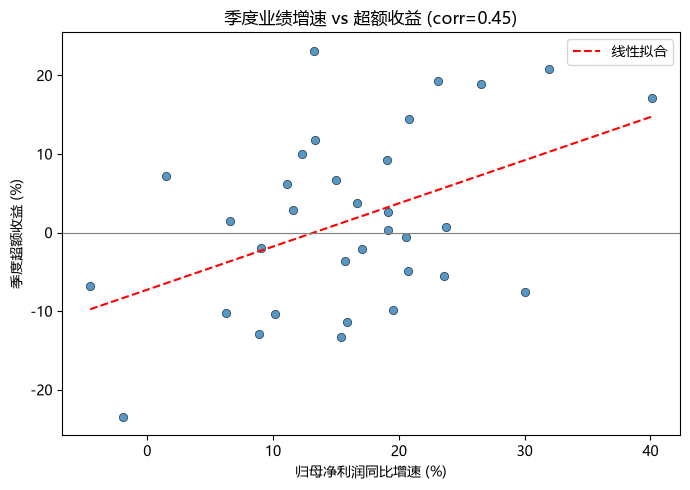

In [9]:
# === 分析2：季度超额收益 vs 业绩增速 散点图 ===
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(qf['netprofit_yoy'], qf['excess'] * 100,
           alpha=0.75, edgecolors='k', linewidths=0.5)
z = np.polyfit(qf['netprofit_yoy'], qf['excess'] * 100, 1)
xline = np.linspace(qf['netprofit_yoy'].min(), qf['netprofit_yoy'].max(), 50)
ax.plot(xline, np.polyval(z, xline), 'r--', lw=1.5, label='线性拟合')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('归母净利润同比增速 (%)')
ax.set_ylabel('季度超额收益 (%)')
ax.set_title(f'季度业绩增速 vs 超额收益 (corr={corr_ex:.2f})')
ax.legend()
fig.tight_layout()
plt.show()

In [10]:
# === 分析3：业绩与估值分解 P = EPS x PE ===
p0, p1 = df['close'].iloc[0], df['close'].iloc[-1]
pe0, pe1 = df['pe_ttm'].iloc[0], df['pe_ttm'].iloc[-1]

total_ret = p1 / p0 - 1                     # 区间总涨幅
pe_ret = pe1 / pe0 - 1                      # 估值(PE)贡献
eps_ret = (p1 / pe1) / (p0 / pe0) - 1       # 业绩(隐含EPS)贡献

print(f'区间: {df["trade_date"].iloc[0].date()} ~ {df["trade_date"].iloc[-1].date()}')
print(f'股价: {p0:.1f} -> {p1:.1f} 元, 总涨幅 {total_ret:+.1%}')
print(f'PE-TTM: {pe0:.1f} -> {pe1:.1f} 倍, 估值贡献 {pe_ret:+.1%}')
print(f'业绩(隐含EPS)贡献: {eps_ret:+.1%}')

# 分解到每个自然年（按当年首个/末个交易日收盘价近似计算）
df['year'] = df['trade_date'].dt.year
rows = []
for y, g in df.groupby('year'):
    if len(g) < 10:
        continue  # 交易日过少的年份跳过
    eps_r = ((g['close'].iloc[-1] / g['pe_ttm'].iloc[-1]) /
             (g['close'].iloc[0] / g['pe_ttm'].iloc[0])) - 1
    rows.append({'年份': y,
                 '股价涨幅%': round((g['close'].iloc[-1] / g['close'].iloc[0] - 1) * 100, 1),
                 '业绩贡献%': round(eps_r * 100, 1),
                 '估值贡献%': round((g['pe_ttm'].iloc[-1] / g['pe_ttm'].iloc[0] - 1) * 100, 1)})
yearly = pd.DataFrame(rows)
yearly

区间: 2018-01-02 ~ 2026-09-30
股价: 703.9 -> 1258.6 元, 总涨幅 +78.8%
PE-TTM: 36.5 -> 19.3 倍, 估值贡献 -47.0%
业绩(隐含EPS)贡献: +237.6%


,年份,股价涨幅%,业绩贡献%,估值贡献%
0,2018,-16.2,31.3,-36.2
1,2019,97.5,28.6,53.6
2,2020,76.8,8.9,62.3
3,2021,2.7,12.5,-8.7
4,2022,-15.8,18.9,-29.2
5,2023,-0.2,19.5,-16.5
6,2024,-9.6,16.1,-22.1
7,2025,-7.4,9.2,-15.3
8,2026,-11.7,-9.4,-2.6


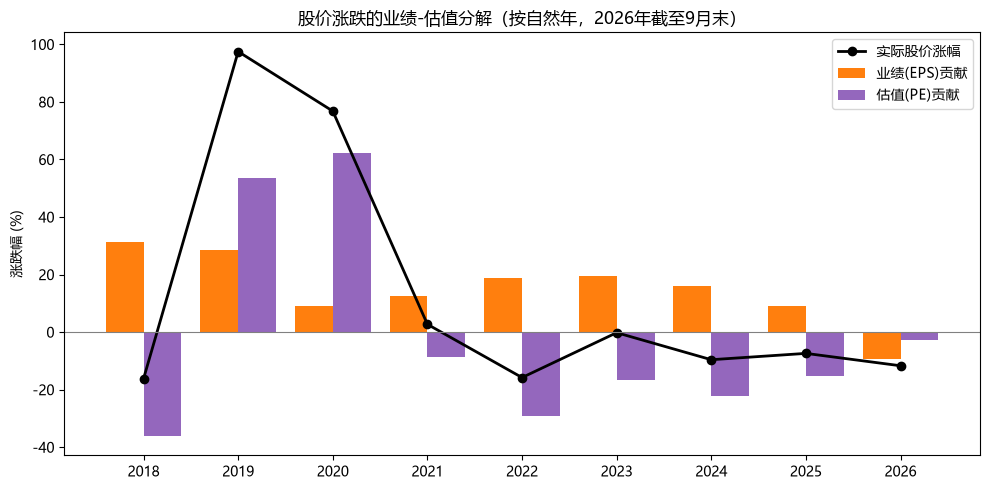

In [11]:
# === 分析3配图：股价涨跌的业绩—估值分解（按年） ===
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(yearly))
ax.bar(x - 0.2, yearly['业绩贡献%'], width=0.4, label='业绩(EPS)贡献', color='tab:orange')
ax.bar(x + 0.2, yearly['估值贡献%'], width=0.4, label='估值(PE)贡献', color='tab:purple')
ax.plot(x, yearly['股价涨幅%'], 'k-o', lw=2, label='实际股价涨幅')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(yearly['年份'])
ax.set_ylabel('涨跌幅 (%)')
ax.set_title('股价涨跌的业绩-估值分解（按自然年，2026年截至9月末）')
ax.legend()
fig.tight_layout()
plt.show()

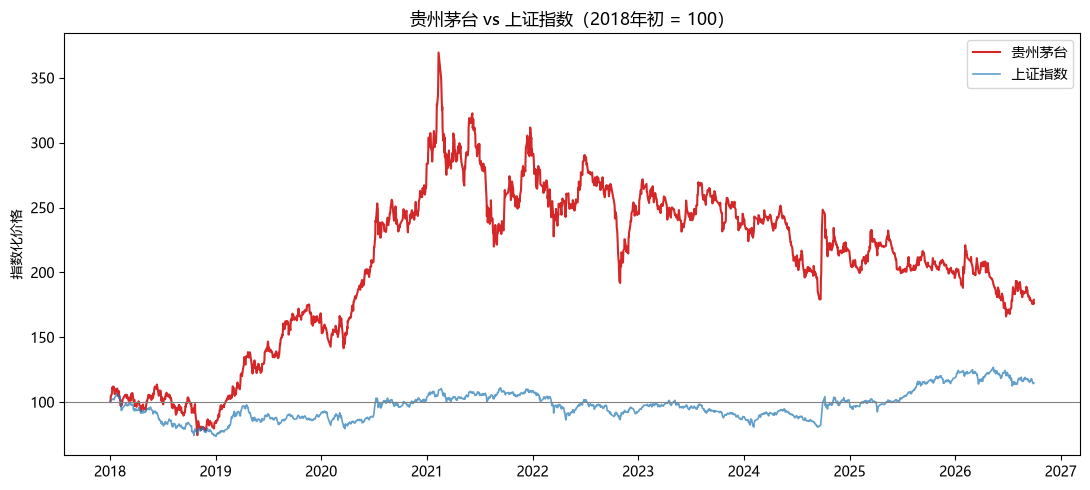

In [12]:
# === 分析4：贵州茅台 vs 上证指数（2018年初=100） ===
norm = df.set_index('trade_date')[['close', 'idx_close']].copy()
norm = norm / norm.iloc[0] * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(norm.index, norm['close'], color='tab:red', lw=1.5, label='贵州茅台')
ax.plot(norm.index, norm['idx_close'], color='tab:blue', lw=1.2, alpha=0.7, label='上证指数')
ax.axhline(100, color='gray', lw=0.8)
ax.set_title('贵州茅台 vs 上证指数（2018年初 = 100）')
ax.set_ylabel('指数化价格')
ax.legend()
fig.tight_layout()
plt.show()

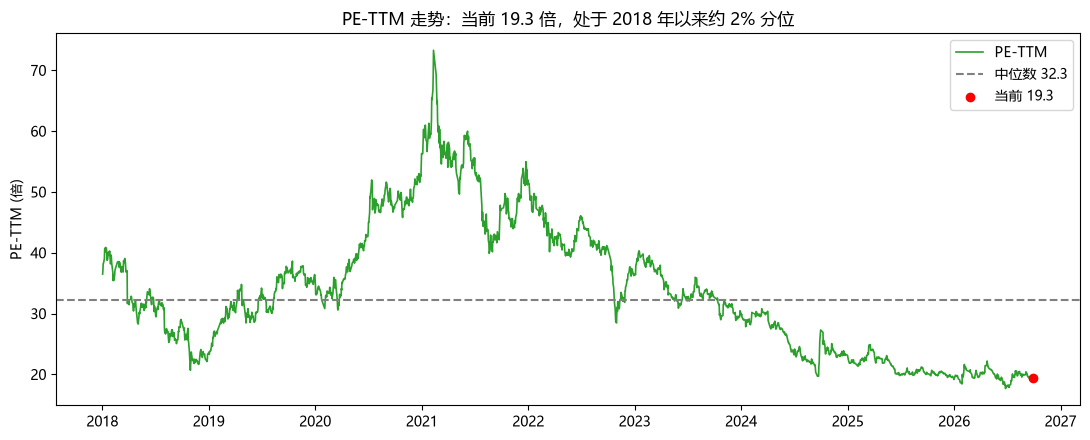

In [13]:
# === 分析5：估值（PE-TTM）走势与历史分位 ===
pe_now = df['pe_ttm'].iloc[-1]
pe_pct = 100 * (df['pe_ttm'] <= pe_now).mean()   # 当前PE在区间内的历史分位

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df['trade_date'], df['pe_ttm'], color='tab:green', lw=1.2, label='PE-TTM')
ax.axhline(df['pe_ttm'].median(), color='gray', ls='--',
           label=f'中位数 {df["pe_ttm"].median():.1f}')
ax.scatter(df['trade_date'].iloc[-1], pe_now, color='red', zorder=5, label=f'当前 {pe_now:.1f}')
ax.set_title(f'PE-TTM 走势：当前 {pe_now:.1f} 倍，处于 2018 年以来约 {pe_pct:.0f}% 分位')
ax.set_ylabel('PE-TTM (倍)')
ax.legend()
fig.tight_layout()
plt.show()

In [14]:
# === 分析6：汇总关键指标，回答研究问题 ===
mdd = ((df['close'] / df['close'].cummax()) - 1).min()       # 区间最大回撤
roe_mean = qf['roe'].mean()
gm_mean = qf['grossprofit_margin'].mean()
ngy_mean = qf['netprofit_yoy'].mean()
e19 = yearly.loc[yearly['年份'] == 2019, '业绩贡献%'].iloc[0]
v19 = yearly.loc[yearly['年份'] == 2019, '估值贡献%'].iloc[0]
e20 = yearly.loc[yearly['年份'] == 2020, '业绩贡献%'].iloc[0]
v20 = yearly.loc[yearly['年份'] == 2020, '估值贡献%'].iloc[0]

print('【研究问题】贵州茅台的股价是业绩驱动还是估值驱动？')
print('=' * 64)
print(f'1. 长期(2018至今): 总涨幅 {total_ret:+.1%} = 业绩贡献 {eps_ret:+.1%} '
      f'+ 估值贡献 {pe_ret:+.1%}')
print('   -> 若估值不变涨幅将超过2倍：长期回报由业绩驱动，估值反而是拖累。')
print(f'2. 中短期: 2019年业绩贡献{e19:+.1f}%、估值贡献{v19:+.1f}%；'
      f'2020年业绩{e20:+.1f}%、估值{v20:+.1f}%')
print('   -> 上涨主要靠估值扩张（情绪驱动）；2021年起估值连年压缩抵消业绩增长。')
print(f'3. 相关性: 单季股价与净利增速 corr={corr_ret:.2f}（情绪扰动大），'
      f'超额收益与净利增速 corr={corr_ex:.2f}（业绩决定相对收益）。')
print(f'4. 当前状态: PE {pe_now:.1f} 倍（约 {pe_pct:.0f}% 历史分位），'
      f'净利增速均值 {ngy_mean:.1f}%、ROE均值 {roe_mean:.1f}%、毛利率均值 {gm_mean:.1f}%')
print(f'   区间最大回撤 {mdd:.1%} -> 好公司也需要好价格。')

【研究问题】贵州茅台的股价是业绩驱动还是估值驱动？
1. 长期(2018至今): 总涨幅 +78.8% = 业绩贡献 +237.6% + 估值贡献 -47.0%
   -> 若估值不变涨幅将超过2倍：长期回报由业绩驱动，估值反而是拖累。
2. 中短期: 2019年业绩贡献+28.6%、估值贡献+53.6%；2020年业绩+8.9%、估值+62.3%
   -> 上涨主要靠估值扩张（情绪驱动）；2021年起估值连年压缩抵消业绩增长。
3. 相关性: 单季股价与净利增速 corr=0.22（情绪扰动大），超额收益与净利增速 corr=0.45（业绩决定相对收益）。
4. 当前状态: PE 19.3 倍（约 2% 历史分位），净利增速均值 16.1%、ROE均值 21.3%、毛利率均值 91.5%
   区间最大回撤 -55.1% -> 好公司也需要好价格。


# 第五部分：研究结论与经验总结

## 研究结论

**总体回答：长期看，茅台股价由业绩驱动；中短期看，估值（市场情绪）是涨跌的主导因素与"放大器"。**

1. **业绩是长期上涨的根本。** 2018-01-02至2026-09-30，股价从703.9元涨至1258.6元（+78.8%）。按 P = EPS × PE 分解，业绩（隐含EPS）贡献 **+237.6%**，估值（PE）贡献 **-47.0%**（PE由36.5倍降至19.3倍）。若估值不变，八年间股价将上涨超过2倍——**是盈利增长撑起了全部长期回报，估值压缩反而是最大拖累**。

2. **估值是中短期波动的主导。**
   - 2019、2020年：业绩贡献仅 +28.6%、+8.9%，估值贡献却高达 +53.6%、+62.3%——**这两年的大牛市主要是估值扩张（戴维斯双击）**；
   - 2021—2025年：净利增速仍保持 +9%~+20% 的正增长，但PE连年压缩（每年 -8.7%~-29.2%），股价因此下跌或滞涨——**业绩增长被估值消化全部抵消**；
   - 2026年（截至9月末）：净利增速转负（约 -9.4%），业绩与估值双杀，股价 -11.7%。

3. **相关性检验支持上述结论。** 33个季度样本中，"股价涨跌幅 vs 净利增速"相关系数仅 **0.22**（单季股价受市场情绪扰动大），而剔除大盘后的"超额收益 vs 净利增速"相关系数达 **0.45**——**业绩决定了能否跑赢大盘，单季度的涨跌则更多由估值情绪决定**。

4. **当前状态与启示。** 当前PE-TTM约19.3倍，处于2018年以来约 **2%的历史分位**（中位数32.3倍），而ROE均值仍达21.3%、毛利率91.5%——市场正以历史最低区域的估值定价一家盈利依然稳健的龙头，反映了对白酒行业的悲观预期；同时区间最大回撤达 **-55.1%**，验证了"**买得太贵，需要用多年的下跌来还账；好公司 ≠ 好股票**"。

## 经验总结

1. **tushare实操经验**
   - 不同接口有调用权限和单次返回条数限制，操作时需注意
   - 要弄清字段口径、代码含义

2. **Agent使用心得**
   - 给出具体可行的操作指令，及时与大模型沟通，有问题迅速提出，同时辅助ai优化成果及语言等，提示词要明晰

3. **分析方法心得**
   - 先把问题转化为可计算的指标（相关系数、分解贡献率、历史分位），再按指标去找数据，分析才有主线。